# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170046        # <-- your full roll number
NAME = "Rupinder kaur"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170046   Name: Rupinder kaur   Fingerprint: 3BACA045   Tickets: 13

Ticket_ID                                                                                   Ticket_Text
      T01                     VPN crashes while opening before the assignment deadline. This is urgent.
      T02     Server has stopped syncing before the assignment deadline. The same problem occurs again.
      T03                                                         I need Windows 11 by 5.30 p.m. today.
      T04                                                     The printer won't print; it isn't jammed.
      T05                                                               Is it fixed?? Pls reply ASAP :(
      T06                                                       The e-mail is not working. Please help.
      T07                        Python is showing an error during the lab. I have tried several times!
      T08                                        The MATLAB failed to open. I have 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code

import pandas as pd

rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)

total = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary["Sentences"].sum(),
    "Tokens": summary["Tokens"].sum(),
    "Punctuation Tokens": summary["Punctuation Tokens"].sum(),
    "Stopwords": summary["Stopwords"].sum(),
    "Unique Tokens": "",
    "Final Tokens": summary["Final Tokens"].sum()
}

summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)

display(summary)




,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,5,12,6
1,T02,2,15,2,6,13,7
2,T03,1,9,1,2,9,6
3,T04,1,11,2,3,10,6
4,T05,2,10,4,2,9,4
5,T06,2,9,2,3,8,4
6,T07,2,15,2,6,15,7
7,T08,2,12,2,4,12,6
8,T09,2,16,2,6,16,8
9,T10,2,10,2,3,9,5


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*The final tokens such as n't, 's, and ca come from contractions in the original tickets. The word_tokenize() function splits contractions into separate tokens, for example, “can't” becomes ca and n't, while “doesn't” becomes does and n't. These fragments are retained in the final tokens because the preprocessing pipeline removes punctuation and stopwords but does not combine contraction parts or check whether each token is a complete word.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][a-zA-Z]*\b"
}

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s]+|www\.[^\s]+"
phone_pattern = r"(?<!\w)(?:\+91[-.\s]?)?(?:\d{5}[-.\s]?\d{5}|\d{4}[-.\s]?\d{3}[-.\s]?\d{4})(?!\w)"

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print("\nTicket:", row["Ticket_ID"])
    print("Words longer than 5 letters:", re.findall(patterns["Words longer than 5 letters"], text))
    print("Numbers:", re.findall(patterns["Numbers"], text))
    print("Capitalized words:", re.findall(patterns["Capitalized words"], text))
    print("Words starting with a vowel:", re.findall(patterns["Words starting with a vowel"], text))

    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)
    print("Replaced text:", cleaned)

for text in TEST_LINES:
    print("\nTest line:", text)
    print("Words longer than 5 letters:", re.findall(patterns["Words longer than 5 letters"], text))
    print("Numbers:", re.findall(patterns["Numbers"], text))
    print("Capitalized words:", re.findall(patterns["Capitalized words"], text))
    print("Words starting with a vowel:", re.findall(patterns["Words starting with a vowel"], text))

    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)
    print("Replaced text:", cleaned)



Ticket: T01
Words longer than 5 letters: ['crashes', 'opening', 'before', 'assignment', 'deadline', 'urgent']
Numbers: []
Capitalized words: ['VPN', 'This']
Words starting with a vowel: ['opening', 'assignment', 'is', 'urgent']
Replaced text: VPN crashes while opening before the assignment deadline. This is urgent.

Ticket: T02
Words longer than 5 letters: ['Server', 'stopped', 'syncing', 'before', 'assignment', 'deadline', 'problem', 'occurs']
Numbers: []
Capitalized words: ['Server', 'The']
Words starting with a vowel: ['assignment', 'occurs', 'again']
Replaced text: Server has stopped syncing before the assignment deadline. The same problem occurs again.

Ticket: T03
Words longer than 5 letters: ['Windows']
Numbers: ['11', '5.30']
Capitalized words: ['I', 'Windows']
Words starting with a vowel: ['I']
Replaced text: I need Windows 11 by 5.30 p.m. today.

Ticket: T04
Words longer than 5 letters: ['printer', 'jammed']
Numbers: []
Capitalized words: ['The']
Words starting with a vowel:

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Most of my capitalized words are capitalized because they appear at the beginning of a sentence, such as This, The, I, and It. Some are capitalized because they are technical names or acronyms, such as VPN, Python, MATLAB, and Windows. Words like Ticket, Call, and Version in the test lines are also capitalized because they begin sentences.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

tokenizer = RegexpTokenizer(
    r"https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d().\s-]*\d|\d+(?:\.\d+)+|[A-Za-z]+(?:[-'][A-Za-z]+)*|\d+|[^\w\s]"
)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print("\n", row["Ticket_ID"], ":", text)
    print("my_tokenize:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))



Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tok

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 3 tickets are tokenized differently by my_tokenize() and word_tokenize(). These are the three test lines containing email addresses, phone numbers, URLs, contractions, and numbers. The remaining 13 tickets have the same tokenization output from both tokenizers.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [12]:
processed = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    processed.append(result)

print("Tickets processed:", len(processed))
print("Example result:", processed[0])

Tickets processed: 13
Example result: {'sentences': ['VPN crashes while opening before the assignment deadline.', 'This is urgent.'], 'tokens': ['vpn', 'crashes', 'while', 'opening', 'before', 'the', 'assignment', 'deadline', '.', 'this', 'is', 'urgent', '.'], 'punct': ['.', '.'], 'stops': ['while', 'before', 'the', 'this', 'is'], 'final': ['vpn', 'crashes', 'opening', 'assignment', 'deadline', 'urgent']}


In [13]:
# Your code


import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r"(ing|ed|s)$", min=5)
lemmatizer = WordNetLemmatizer()

if isinstance(processed, dict):
    results = processed.values()
else:
    results = processed

unique_tokens = sorted(set(
    token
    for result in results
    for token in result["final"]
))

tagged_words = pos_tag(unique_tokens)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

rows = []

for word, tag in tagged_words:
    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regex_word = regex_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len(set([porter_word, lancaster_word, regex_word, lemma_word])) > 1:
        rows.append({
            "Word": word,
            "Porter Stem": porter_word,
            "Lancaster Stem": lancaster_word,
            "Regexp Stem": regex_word,
            "WordNet Lemma": lemma_word
        })

comparison = pd.DataFrame(
    rows,
    columns=["Word", "Porter Stem", "Lancaster Stem", "Regexp Stem", "WordNet Lemma"]
)

display(comparison)



,Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,assignment,assign,assign,assignment,assignment
1,crashes,crash,crash,crashe,crash
2,deadline,deadlin,deadlin,deadline,deadline
3,error,error,er,error,error
4,jammed,jam,jam,jamm,jam
5,latest,latest,latest,latest,late
6,need,need,nee,need,need
7,occurs,occur,occ,occur,occurs
8,open,open,op,open,open
9,opening,open,op,open,open


In [14]:
print("Type of processed:", type(processed))
print("Number of processed items:", len(processed))

if isinstance(processed, dict):
    results = list(processed.values())
else:
    results = list(processed)

print("First processed item:", results[0] if results else "Empty")

Type of processed: <class 'list'>
Number of processed items: 13
First processed item: {'sentences': ['VPN crashes while opening before the assignment deadline.', 'This is urgent.'], 'tokens': ['vpn', 'crashes', 'while', 'opening', 'before', 'the', 'assignment', 'deadline', '.', 'this', 'is', 'urgent', '.'], 'punct': ['.', '.'], 'stops': ['while', 'before', 'the', 'this', 'is'], 'final': ['vpn', 'crashes', 'opening', 'assignment', 'deadline', 'urgent']}


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Over-stemming: error → er by Lancaster Stemmer, as it removes too much of the word. Under-stemming: crashes → crashe by RegexpStemmer, as it fails to reduce the word to its proper stem, crash

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,156,77,0.4936
1,S2,129,70,0.5426
2,S3,78,53,0.6795
3,S4,78,51,0.6538



Top 10 words in S1:
   Word  Frequency
      .         18
    the         13
     is          7
      i          6
     it          4
  tried          4
   have          3
several          3
  times          3
      !          3

Top 10 words in S3:
      Word  Frequency
     tried          4
   several          3
     times          3
 yesterday          3
   crashes          2
   opening          2
assignment          2
  deadline          2
    server          2
   problem          2


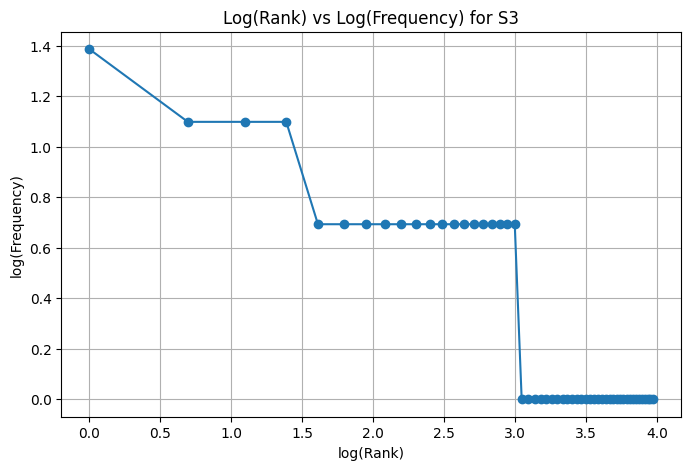


Top 5 bigrams in S1:
          Bigram  Frequency
          (., i)          6
        (., the)          3
       (i, have)          3
   (have, tried)          3
(tried, several)          3

Top 5 bigrams in S3:
                Bigram  Frequency
      (tried, several)          3
      (several, times)          3
    (crashes, opening)          2
(assignment, deadline)          2
     (problem, occurs)          2


In [15]:
# Your code

import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if t not in result["punct"]])
    S3.extend(result["final"])

S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1": S1,
    "S2": S2,
    "S3": S3,
    "S4": S4
}

stats = []

for name, tokens in corpora.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

display(pd.DataFrame(stats))

print("\nTop 10 words in S1:")
print(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]).to_string(index=False))

print("\nTop 10 words in S3:")
print(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]).to_string(index=False))

freq = Counter(S3)
ranked = freq.most_common()

ranks = list(range(1, len(ranked) + 1))
frequencies = [count for _, count in ranked]

plt.figure(figsize=(8, 5))
plt.plot([math.log(r) for r in ranks],
         [math.log(f) for f in frequencies],
         marker="o",
         linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("\nTop 5 bigrams in S1:")
print(pd.DataFrame(Counter(bigrams(S1)).most_common(5), columns=["Bigram", "Frequency"]).to_string(index=False))

print("\nTop 5 bigrams in S3:")
print(pd.DataFrame(Counter(bigrams(S3)).most_common(5), columns=["Bigram", "Frequency"]).to_string(index=False))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR decreases from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter stemming converts different forms of words into common stems. This reduces the number of unique tokens relative to the total number of tokens. As a result, S4 generally has a lower TTR than S1 in my dataset.